# Lecture 16

Today's Topics:

- Debugging a Network
- Validation Sets
- Loss Curves: Underfitting vs. Overfitting
- Optimizers & Learning Rate
- Regularization: Dropout & Weight Decay
- Data Augmentation
- Early Stopping

In [5]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split

import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor

print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}")

PyTorch version: 2.15.0+cu132
torchvision version: 0.29.2+cu132


In [6]:
# Device-agnostic code: use the GPU if there is one, otherwise the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

We'll keep working with FashionMNIST from lecture 14 and 15.

In [7]:
train_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=ToTensor())
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=ToTensor())

class_names = train_data.classes
len(train_data), len(test_data)

(60000, 10000)

In [8]:
BATCH_SIZE = 32

def accuracy_fn(y_true, y_pred):
    # Calculates accuracy (as a percentage) between truth labels and predictions
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100

## Debugging a Network

Last time we built three models:

- `model_0` - two `nn.Linear()` layers (~83% test accuracy)
- `model_1` - the same, with `nn.ReLU()` layers added (~75% test accuracy)
- `model_2` - a CNN (TinyVGG) (~88% test accuracy)

We expected the non-linear model to do *better* than the linear one, and it did worse. We blamed overfitting. Let's look closer, because the numbers don't support that:

```
Train loss: 0.67027 | Train accuracy: 75.94%
Test loss: 0.68500 | Test accuracy: 75.02%
```

An overfit model does much better on the data it trained on than on new data. Here train and test accuracy are almost identical. The model isn't memorizing the training set, it just isn't learning well on *either* set. That's called **underfitting**.

So what's wrong? Look at the last layer:

In [9]:
class FashionMNISTModelV1(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_shape),
            nn.ReLU()  # <- here
        )

    def forward(self, x: torch.Tensor):
        return self.layer_stack(x)

The model ends in a `nn.ReLU()`. The outputs of the final layer are the **logits**, the raw scores that `nn.CrossEntropyLoss()` turns into probabilities with softmax.

To say "this image is definitely *not* a sandal", the model needs to push the sandal logit to a large negative number. But ReLU replaces every negative number with 0:

$$\text{ReLU}(a) = \max(0, a)$$

And on top of that, ReLU's slope is 0 for negative inputs, so no gradient flows back through those outputs. Once a class's logit gets stuck below 0, the model can't learn anything more about that class from that example.

Let's train the model like last time and then look at what comes out of it.

First, our `train_step()` and `test_step()` functions from last lecture, with two changes:

1. They **return** the loss and accuracy instead of only printing them, so we can plot them later.
2. `train_step()` now calls `model.train()`. Last lecture's version never did, and `test_step()` calls `model.eval()`, so after the first epoch the model was stuck in evaluation mode. That didn't matter for our layers so far, but it will matter for dropout later today.

In [10]:
def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn,
               device: torch.device = device):
    train_loss, train_acc = 0, 0
    model.to(device)
    model.train() # put model in training mode
    for X, y in data_loader:
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate loss and accuracy
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()
        train_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

    # Average loss and accuracy per batch
    train_loss /= len(data_loader)
    train_acc /= len(data_loader)
    return train_loss, train_acc


def test_step(model: torch.nn.Module,
              data_loader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              accuracy_fn,
              device: torch.device = device):
    test_loss, test_acc = 0, 0
    model.to(device)
    model.eval() # put model in eval mode
    with torch.inference_mode():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)

            # 1. Forward pass
            test_pred = model(X)

            # 2. Calculate loss and accuracy
            test_loss += loss_fn(test_pred, y).item()
            test_acc += accuracy_fn(y_true=y, y_pred=test_pred.argmax(dim=1))

    test_loss /= len(data_loader)
    test_acc /= len(data_loader)
    return test_loss, test_acc

In [11]:
train_dataloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

loss_fn = nn.CrossEntropyLoss()

torch.manual_seed(42)
model_1 = FashionMNISTModelV1(input_shape=784, hidden_units=10, output_shape=len(class_names))
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.1)

for epoch in range(3):
    train_loss, train_acc = train_step(model_1, train_dataloader, loss_fn, optimizer, accuracy_fn)
    test_loss, test_acc = test_step(model_1, test_dataloader, loss_fn, accuracy_fn)
    print(f"Epoch {epoch} | Train loss: {train_loss:.4f}, acc: {train_acc:.2f}% | Test loss: {test_loss:.4f}, acc: {test_acc:.2f}%")

Epoch 0 | Train loss: 1.0588, acc: 62.19% | Test loss: 0.9951, acc: 64.13%
Epoch 1 | Train loss: 0.9133, acc: 66.40% | Test loss: 0.9051, acc: 66.86%
Epoch 2 | Train loss: 0.8798, acc: 67.25% | Test loss: 0.8949, acc: 66.47%


This run landed around 66%, even lower than the 75% we got last time. How badly this model does depends on its random starting weights, which is itself a hint that something is not right. A good model shouldn't swing that much between runs.

Now let's look at the logits for a batch of test images.

In [12]:
X_batch, y_batch = next(iter(test_dataloader))

model_1.eval()
with torch.inference_mode():
    logits = model_1(X_batch.to(device))

print("Logits for the first 3 images:")
print(logits[:3].round(decimals=2))
print(f"\nFraction of logits that are exactly 0: {(logits == 0).float().mean().item():.1%}")

Logits for the first 3 images:
tensor([[ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0500,  0.0000,  1.2200,
          0.0000,  0.0000],
        [ 2.8400,  0.0000, 10.1800,  0.0000,  4.7000,  0.0000,  7.1800,  0.0000,
          1.3900,  0.0000],
        [ 2.4200, 13.8200,  0.0000,  0.0000,  4.1900,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000]])

Fraction of logits that are exactly 0: 70.6%


A large share of the outputs are exactly 0. When several classes are tied at 0, the model has no way to say which of them is more likely, and no gradient to learn from.

One way we can fix it is by: **not putting an activation function after the output layer**. `nn.CrossEntropyLoss()` expects raw logits, so the last layer should be a plain `nn.Linear()`.

In [13]:
class FashionMNISTModelV1Fixed(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_shape)  # no ReLU on the output
        )

    def forward(self, x: torch.Tensor):
        return self.layer_stack(x)

torch.manual_seed(42)
model_1_fixed = FashionMNISTModelV1Fixed(input_shape=784, hidden_units=10, output_shape=len(class_names))
optimizer = torch.optim.SGD(params=model_1_fixed.parameters(), lr=0.1)

for epoch in range(3):
    train_loss, train_acc = train_step(model_1_fixed, train_dataloader, loss_fn, optimizer, accuracy_fn)
    test_loss, test_acc = test_step(model_1_fixed, test_dataloader, loss_fn, accuracy_fn)
    print(f"Epoch {epoch} | Train loss: {train_loss:.4f}, acc: {train_acc:.2f}% | Test loss: {test_loss:.4f}, acc: {test_acc:.2f}%")

Epoch 0 | Train loss: 0.6443, acc: 77.08% | Test loss: 0.5419, acc: 80.68%
Epoch 1 | Train loss: 0.4785, acc: 83.19% | Test loss: 0.4659, acc: 83.53%
Epoch 2 | Train loss: 0.4444, acc: 84.48% | Test loss: 0.4906, acc: 83.20%


With the issue removed, the non-linear model jumps from ~66% to ~83%, the same level as the linear baseline. With only 10 hidden units and 3 epochs there isn't much room for the non-linearity to pull ahead yet, but the model is no longer crippled, and the rest of today is about getting more out of it.

### Sanity check: overfit one batch

Another standard way to test: before training on the full dataset, make sure the model can **memorize a single batch**. A working model with enough parameters should drive the loss on 32 examples close to zero. If it can't, something in the model, loss, or training loop is broken.

In [14]:
def overfit_one_batch(model, X, y, steps=200, lr=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for step in range(steps):
        loss = loss_fn(model(X), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return loss.item()

X_one, y_one = next(iter(train_dataloader))

torch.manual_seed(42)
broken = FashionMNISTModelV1(784, 10, len(class_names))
torch.manual_seed(42)
fixed = FashionMNISTModelV1Fixed(784, 10, len(class_names))

print(f"V1 (ReLU on output) final loss on one batch: {overfit_one_batch(broken, X_one, y_one):.4f}")
print(f"V1 fixed            final loss on one batch: {overfit_one_batch(fixed, X_one, y_one):.4f}")

V1 (ReLU on output) final loss on one batch: 0.5063
V1 fixed            final loss on one batch: 0.0007


## Validation Sets

So far we've checked the test set after every epoch and used it to decide which model was best. That's a problem: if we keep making choices based on the test set (which model, how many epochs, which learning rate), we're slowly fitting our choices to it, and the test accuracy stops being an honest estimate of how the model does on new data.

The fix is to split our data three ways:

| Split | Used for |
|---|---|
| **Training set** | Fitting the model's parameters |
| **Validation set** | Comparing models, tuning settings, deciding when to stop |
| **Test set** | One final evaluation, at the very end |

FashionMNIST gives us 60,000 training images and 10,000 test images. We'll carve 10,000 validation images out of the training set with `random_split()`.

In [15]:
train_split, val_split = random_split(train_data, [50_000, 10_000],
                                      generator=torch.Generator().manual_seed(42))

val_dataloader = DataLoader(val_split, batch_size=BATCH_SIZE, shuffle=False)

len(train_split), len(val_split)

(50000, 10000)

Next, a `fit()` function that runs `train_step()` and `test_step()` for several epochs and keeps a **history** of the loss and accuracy so we can plot them. (We'll add early stopping to it later.)

In [16]:
def fit(model, train_dataloader, val_dataloader, loss_fn, optimizer,
        epochs, print_every=5, device=device):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        train_loss, train_acc = train_step(model, train_dataloader, loss_fn, optimizer, accuracy_fn, device)
        val_loss, val_acc = test_step(model, val_dataloader, loss_fn, accuracy_fn, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if epoch % print_every == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch:2d} | Train loss: {train_loss:.4f}, acc: {train_acc:.2f}% "
                  f"| Val loss: {val_loss:.4f}, acc: {val_acc:.2f}%")
    return history


def plot_history(histories: dict, title=""):
    # Plots train (dashed) and validation (solid) curves for one or more models
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for i, (name, h) in enumerate(histories.items()):
        color = f"C{i}"
        epochs = range(1, len(h["train_loss"]) + 1)
        axes[0].plot(epochs, h["train_loss"], "--", color=color, label=f"{name} (train)")
        axes[0].plot(epochs, h["val_loss"], "-", color=color, label=f"{name} (val)")
        axes[1].plot(epochs, h["train_acc"], "--", color=color, label=f"{name} (train)")
        axes[1].plot(epochs, h["val_acc"], "-", color=color, label=f"{name} (val)")
    axes[0].set_title("Loss")
    axes[1].set_title("Accuracy (%)")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## Loss Curves: Underfitting vs. Overfitting

The single most useful picture when training a network is the **train vs. validation loss curve**. It tells you which of two problems you have:

- **Underfitting**: the model can't even fit the training data. Train and validation loss are both high and close together.
- **Overfitting**: the model fits the training data *too* well, memorizing details that don't generalize. Train loss keeps going down while validation loss stops improving or goes back up.

To see both clearly (and to keep training fast), let's pretend we only have **2,000 labeled images**. Small datasets are where overfitting shows up most.

In [20]:
import networkx as nx
import matplotlib.pyplot as plt

def draw_mlp(ax, layer_sizes, layer_names, title, max_shown=6):
    """Draw a fully connected network. Large layers show their first and last
    few neurons with a vertical ellipsis in between."""
    G = nx.DiGraph()
    pos, labels, colors = {}, {}, {}
    layers = []  # node names for each layer (excluding ellipsis nodes)
    prefixes = ["x"] + ["h"] * (len(layer_sizes) - 2) + ["y"]
    palette = ["lightblue"] + ["lightgreen"] * (len(layer_sizes) - 2) + ["salmon"]

    # Shared bottom edge so all layer captions line up
    bottom = -(min(max(layer_sizes), max_shown) - 1) / 2

    for l, n in enumerate(layer_sizes):
        # Which neuron indices to draw
        if n <= max_shown:
            shown = list(range(1, n + 1))
        else:
            shown = [1, 2, 3, None, n - 1, n]  # None = ellipsis

        nodes = []
        top = (len(shown) - 1) / 2
        for k, i in enumerate(shown):
            y = top - k
            if i is None:
                ax.text(l * 3, y, r"$\vdots$", ha="center", va="center", fontsize=18)
                continue
            name = f"L{l}_{i}"
            G.add_node(name)
            pos[name] = (l * 3, y)
            labels[name] = rf"${prefixes[l]}_{{{i}}}$"
            colors[name] = palette[l]
            nodes.append(name)
        layers.append(nodes)

        # Layer name and size underneath
        ax.text(l * 3, bottom - 1.0, f"{layer_names[l]}\n{n} units",
                ha="center", va="top", fontsize=10)

    # Fully connected: every drawn node to every drawn node in the next layer
    for a, b in zip(layers[:-1], layers[1:]):
        G.add_edges_from((u, v) for u in a for v in b)

    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="gray", alpha=0.4,
                           arrows=False, width=0.8)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=900,
                           node_color=[colors[n] for n in G.nodes],
                           edgecolors="black", linewidths=0.8)
    nx.draw_networkx_labels(G, pos, labels=labels, ax=ax, font_size=9)

    n_params = sum(a * b + b for a, b in zip(layer_sizes[:-1], layer_sizes[1:]))
    ax.set_title(f"{title}\n{n_params:,} parameters", fontsize=12)
    ax.axis("off")
    ax.margins(0.15)

In [17]:
small_indices = train_split.indices[:2000]
small_train = Subset(train_data, small_indices)

small_train_dataloader = DataLoader(small_train, batch_size=BATCH_SIZE, shuffle=True)
len(small_train)

2000

### An underfitting model

A network with only **2 hidden units** squeezes each 784-pixel image down to 2 numbers before classifying it. There isn't enough room to represent 10 kinds of clothing.

We'll use the `Adam` optimizer here; we'll talk about what it does in just a second.

In [23]:
torch.manual_seed(42)
tiny_model = nn.Sequential(
    # 784 -> 2 -> 10
    nn.Flatten(),
    nn.Linear(784, 2),
    nn.ReLU(),
    nn.Linear(2, 10)
)
optimizer = torch.optim.Adam(tiny_model.parameters(), lr=0.001)

tiny_history = fit(tiny_model, small_train_dataloader, val_dataloader, loss_fn, optimizer, epochs=30)

Epoch  0 | Train loss: 2.2972, acc: 9.62% | Val loss: 2.2180, acc: 10.34%
Epoch  5 | Train loss: 1.9813, acc: 19.39% | Val loss: 1.9617, acc: 20.48%
Epoch 10 | Train loss: 1.8567, acc: 21.43% | Val loss: 1.8499, acc: 22.06%
Epoch 15 | Train loss: 1.7933, acc: 23.31% | Val loss: 1.7954, acc: 21.87%
Epoch 20 | Train loss: 1.7503, acc: 23.31% | Val loss: 1.7578, acc: 22.58%
Epoch 25 | Train loss: 1.7175, acc: 23.66% | Val loss: 1.7303, acc: 23.29%
Epoch 29 | Train loss: 1.6974, acc: 24.06% | Val loss: 1.7126, acc: 24.07%


### An overfitting model

Now the opposite: two hidden layers of **512 units** each. That's over 600,000 parameters for 2,000 images, plenty of room to memorize every training example.

In [19]:
def make_big_model(dropout=0.0):
    # 784 -> 512 -> 512 -> 10, with optional dropout after each hidden layer
    layers = [nn.Flatten(), nn.Linear(784, 512), nn.ReLU()]
    if dropout > 0:
        layers.append(nn.Dropout(p=dropout))
    layers += [nn.Linear(512, 512), nn.ReLU()]
    if dropout > 0:
        layers.append(nn.Dropout(p=dropout))
    layers.append(nn.Linear(512, 10))
    return nn.Sequential(*layers)

torch.manual_seed(42)
big_model = make_big_model()
print(f"Parameters: {sum(p.numel() for p in big_model.parameters()):,}")

optimizer = torch.optim.Adam(big_model.parameters(), lr=0.001)
big_history = fit(big_model, small_train_dataloader, val_dataloader, loss_fn, optimizer, epochs=30)

Parameters: 669,706
Epoch  0 | Train loss: 1.1097, acc: 59.57% | Val loss: 0.7850, acc: 71.94%
Epoch  5 | Train loss: 0.4470, acc: 83.58% | Val loss: 0.5771, acc: 80.89%
Epoch 10 | Train loss: 0.2964, acc: 88.59% | Val loss: 0.5185, acc: 83.27%
Epoch 15 | Train loss: 0.2214, acc: 91.52% | Val loss: 0.5626, acc: 81.97%
Epoch 20 | Train loss: 0.1762, acc: 93.65% | Val loss: 0.6646, acc: 81.78%
Epoch 25 | Train loss: 0.0984, acc: 96.73% | Val loss: 0.7404, acc: 83.39%
Epoch 29 | Train loss: 0.1359, acc: 94.54% | Val loss: 0.7813, acc: 81.94%


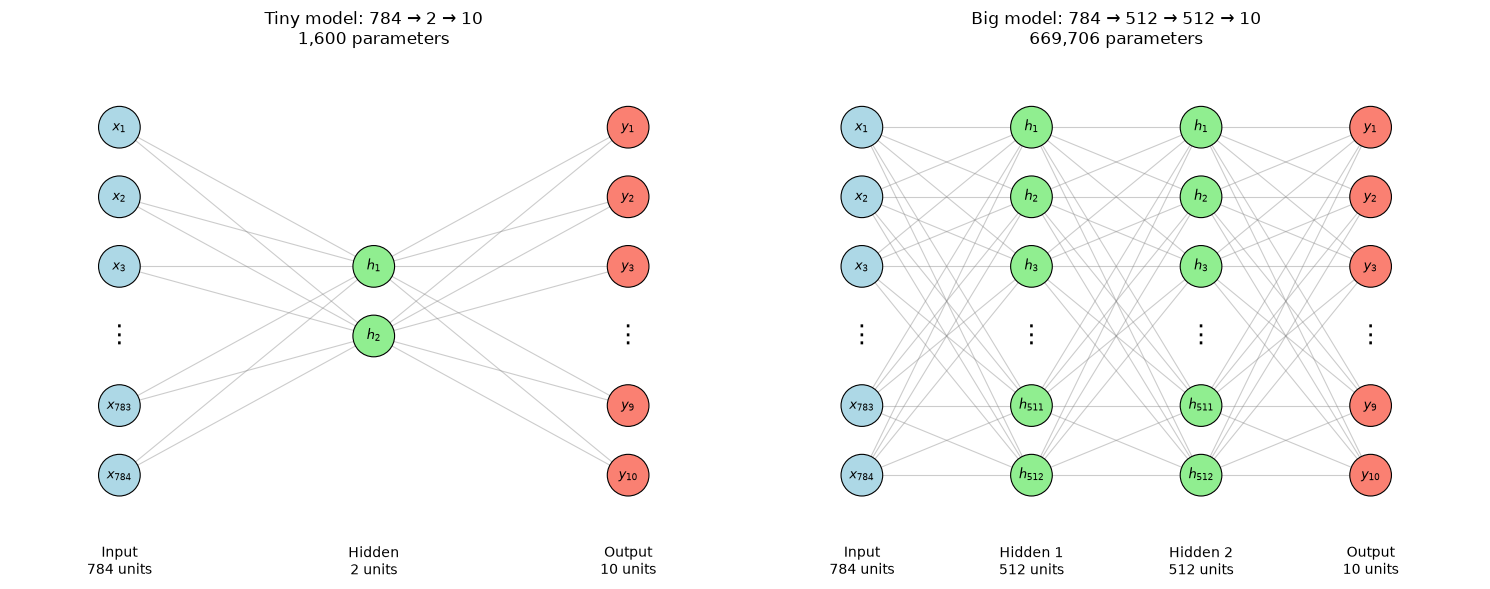

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

draw_mlp(axes[0], [784, 2, 10],
         ["Input", "Hidden", "Output"],
         "Tiny model: 784 → 2 → 10")

draw_mlp(axes[1], [784, 512, 512, 10],
         ["Input", "Hidden 1", "Hidden 2", "Output"],
         "Big model: 784 → 512 → 512 → 10")

plt.tight_layout()
plt.show()

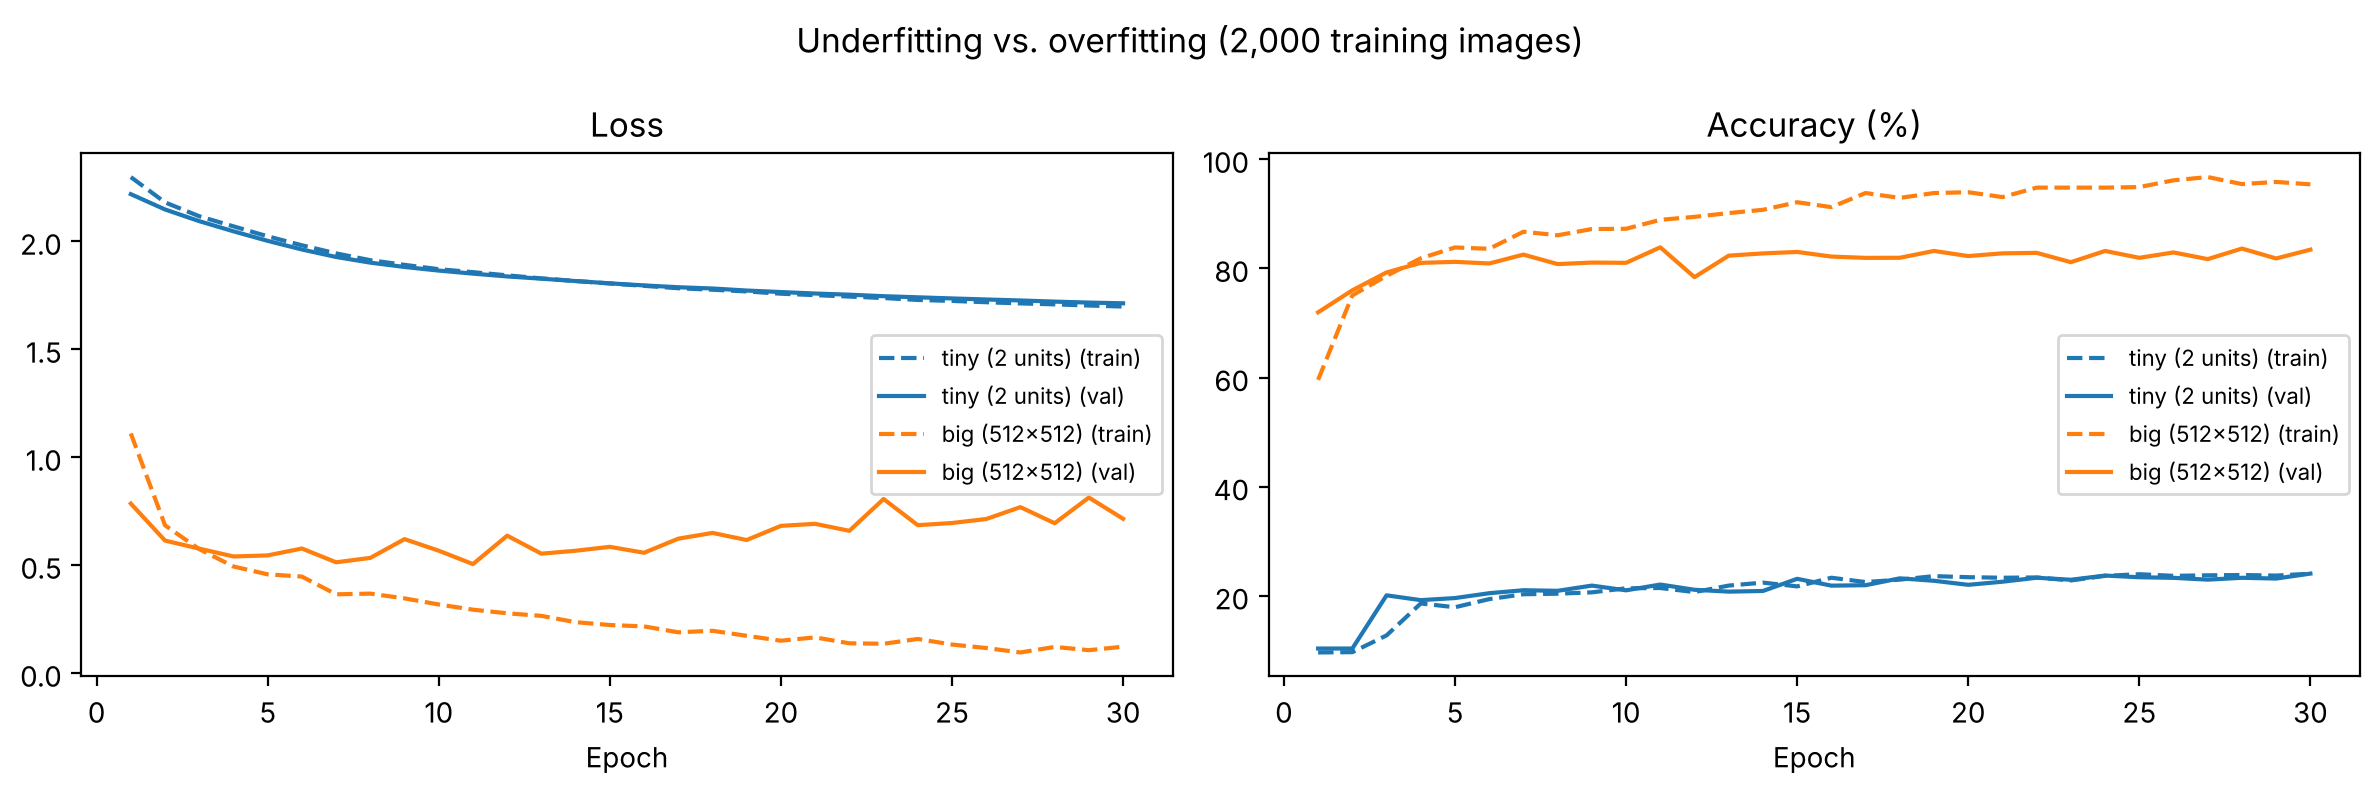

In [16]:
plot_history({"tiny (2 units)": tiny_history, "big (512x512)": big_history},
             title="Underfitting vs. overfitting (2,000 training images)")

Reading the curves:

- **Tiny model**: train and validation curves sit close together, and both plateau at a high loss and low accuracy. More training won't help. It's underfitting.
- **Big model**: training loss keeps dropping and training accuracy climbs toward 100%, but validation loss bottoms out early and then *rises*. The gap between the dashed and solid lines is the model memorizing the training set. It's overfitting.

| Problem | Diagnosis | Things to try |
|---|---|---|
| Train and val loss both high, close together | Underfitting | Bigger model, train longer, adjust learning rate, check for bugs |
| Train loss low, val loss rising, big gap | Overfitting | More data, data augmentation, dropout, weight decay, early stopping, smaller model |

Most of the rest of today is about the right-hand column: ways to fight overfitting.

## Optimizers & Learning Rate

Recall that training updates each parameter $w$ by taking a step against its gradient:

$$w \leftarrow w - \eta \cdot \frac{\partial L}{\partial w}$$

where $\eta$ is the **learning rate**. This is plain **stochastic gradient descent (SGD)**, what we've used so far with `torch.optim.SGD`. ("Stochastic" because each step uses a random batch instead of the whole dataset.)

The learning rate is usually the most important setting to get right. Here's gradient descent on a simple function, $L(w) = w^2$, starting at $w = 4$ with three different learning rates:

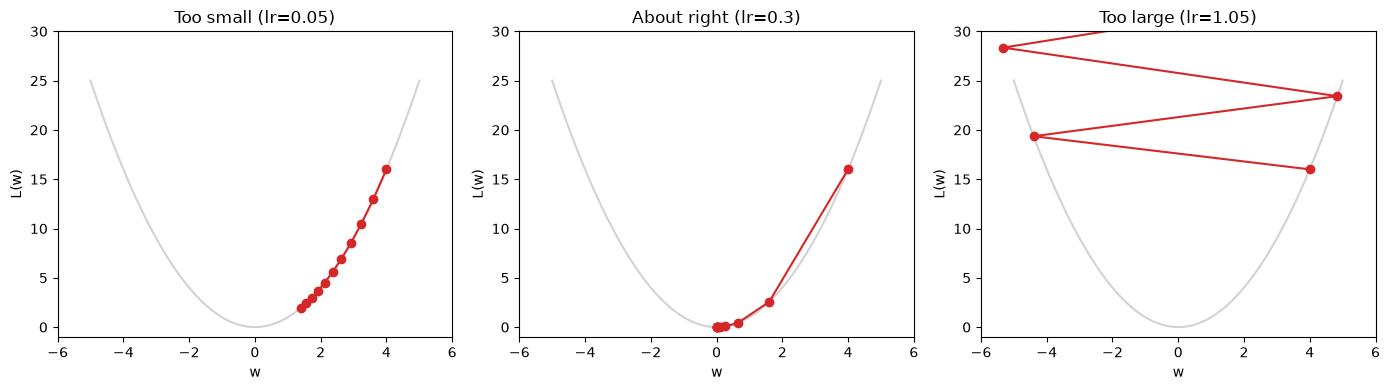

In [22]:
def gradient_descent_1d(lr, w0=4.0, steps=10):
    ws = [w0]
    for _ in range(steps):
        grad = 2 * ws[-1]          # derivative of w^2
        ws.append(ws[-1] - lr * grad)
    return np.array(ws)

w_grid = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (lr, title) in zip(axes, [(0.05, "Too small (lr=0.05)"),
                                  (0.3, "About right (lr=0.3)"),
                                  (1.05, "Too large (lr=1.05)")]):
    ws = gradient_descent_1d(lr)
    ax.plot(w_grid, w_grid**2, color="lightgray")
    ax.plot(ws, ws**2, "o-", color="C3")
    ax.set_title(title)
    ax.set_xlabel("w")
    ax.set_ylabel("L(w)")
    ax.set_xlim(-6, 6)
    ax.set_ylim(-1, 30)

plt.tight_layout()
plt.show()

- **Too small**: every step moves in the right direction, but it takes forever to get anywhere.
- **About right**: the loss drops quickly to the minimum.
- **Too large**: each step overshoots past the minimum, and the loss gets *worse* every step. This is called **diverging**.

Let's see the same thing on a real network: a small model (one hidden layer of 128 units) trained on 10,000 images with different learning rates.

In [18]:
medium_train = Subset(train_data, train_split.indices[:10_000])
medium_train_dataloader = DataLoader(medium_train, batch_size=BATCH_SIZE, shuffle=True)

def make_mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))

lr_histories = {}
for lr in [0.001, 0.1, 1.0]:
    print(f"\nSGD lr={lr}")
    torch.manual_seed(42)
    model = make_mlp()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    lr_histories[f"SGD lr={lr}"] = fit(model, medium_train_dataloader, val_dataloader,
                                       loss_fn, optimizer, epochs=10, print_every=3)


SGD lr=0.001


Epoch  0 | Train loss: 2.2202, acc: 16.05% | Val loss: 2.1439, acc: 29.00%


Epoch  3 | Train loss: 1.7772, acc: 61.42% | Val loss: 1.6990, acc: 62.56%


Epoch  6 | Train loss: 1.3944, acc: 63.96% | Val loss: 1.3422, acc: 63.81%


Epoch  9 | Train loss: 1.1680, acc: 65.31% | Val loss: 1.1373, acc: 65.03%

SGD lr=0.1


Epoch  0 | Train loss: 0.8883, acc: 67.86% | Val loss: 0.7425, acc: 74.22%


... (3 outputs left out)

Epoch  0 | Train loss: 2.3707, acc: 12.47% | Val loss: 2.3225, acc: 11.63%


Epoch  3 | Train loss: 2.3096, acc: 10.04% | Val loss: 2.3061, acc: 10.34%


Epoch  6 | Train loss: 2.3096, acc: 10.04% | Val loss: 2.3123, acc: 9.98%


Epoch  9 | Train loss: 2.3102, acc: 9.91% | Val loss: 2.3119, acc: 9.86%


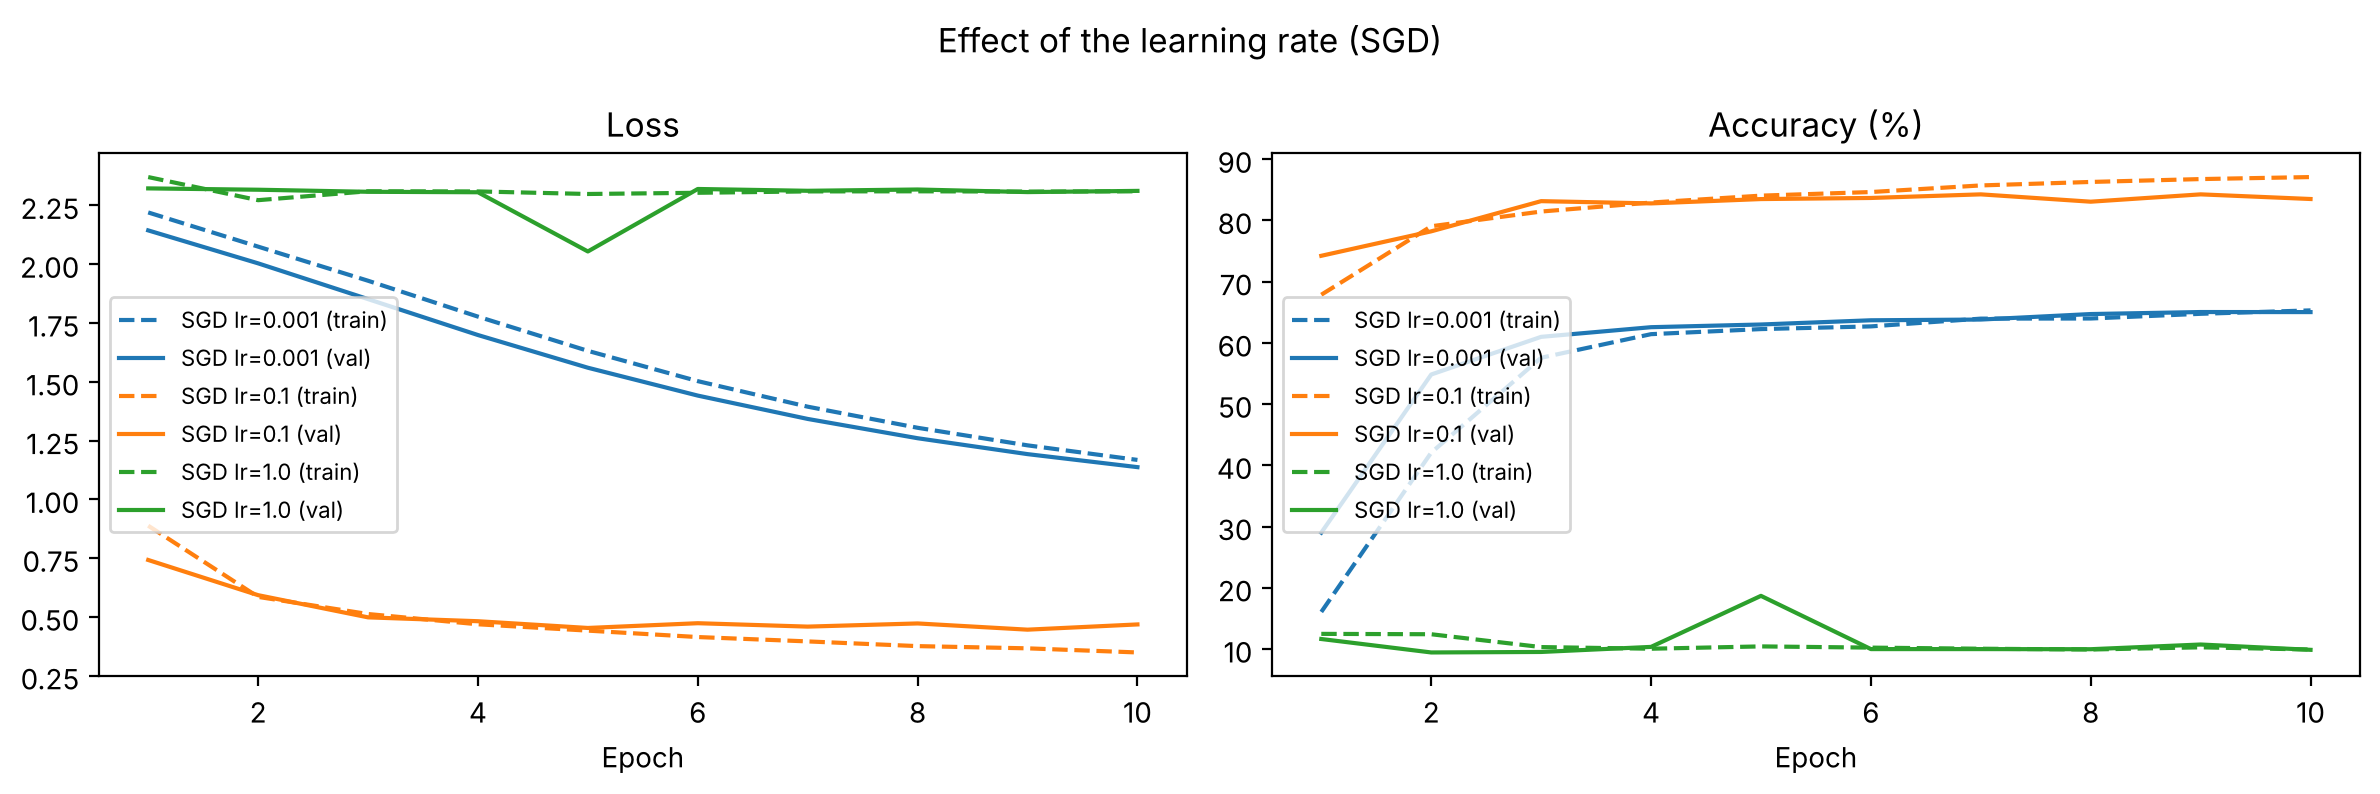

In [19]:
plot_history(lr_histories, title="Effect of the learning rate (SGD)")

The same pattern as the toy example:

- `lr=0.001` is learning, but slowly. After 10 epochs it's still far behind.
- `lr=0.1` trains well.
- `lr=1.0` is too large. The loss jumps up and the model ends up stuck around 10% accuracy, which is random guessing for 10 classes.

### Momentum and Adam

Plain SGD has two weaknesses: it can zig-zag when the loss surface is steep in one direction and flat in another, and it uses the same step size for every parameter. Two popular improvements:

- **Momentum** keeps a running average of recent gradients and steps in that direction, like a ball rolling downhill that builds up speed. Steps that agree add up; steps that zig-zag cancel out. In PyTorch: `torch.optim.SGD(params, lr=0.01, momentum=0.9)`.
- **Adam** combines momentum with a separate, automatically adjusted step size for each parameter. It's forgiving about the learning rate, and `lr=0.001` is a good default for most problems. In PyTorch: `torch.optim.Adam(params, lr=0.001)`.

In [20]:
opt_histories = {"SGD lr=0.1": lr_histories["SGD lr=0.1"]}

print("SGD + momentum")
torch.manual_seed(42)
model = make_mlp()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
opt_histories["SGD momentum"] = fit(model, medium_train_dataloader, val_dataloader,
                                    loss_fn, optimizer, epochs=10, print_every=3)

print("\nAdam")
torch.manual_seed(42)
model = make_mlp()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
opt_histories["Adam"] = fit(model, medium_train_dataloader, val_dataloader,
                            loss_fn, optimizer, epochs=10, print_every=3)

SGD + momentum


Epoch  0 | Train loss: 0.8944, acc: 68.12% | Val loss: 0.6454, acc: 78.17%


Epoch  3 | Train loss: 0.4595, acc: 83.62% | Val loss: 0.5059, acc: 82.25%


Epoch  6 | Train loss: 0.3936, acc: 85.60% | Val loss: 0.4689, acc: 83.95%


Epoch  9 | Train loss: 0.3446, acc: 87.38% | Val loss: 0.4412, acc: 85.08%

Adam


Epoch  0 | Train loss: 0.7754, acc: 72.61% | Val loss: 0.6216, acc: 78.34%


Epoch  3 | Train loss: 0.4283, acc: 84.63% | Val loss: 0.4783, acc: 83.63%


Epoch  6 | Train loss: 0.3600, acc: 86.88% | Val loss: 0.4357, acc: 85.04%


Epoch  9 | Train loss: 0.3069, acc: 88.75% | Val loss: 0.4283, acc: 86.07%


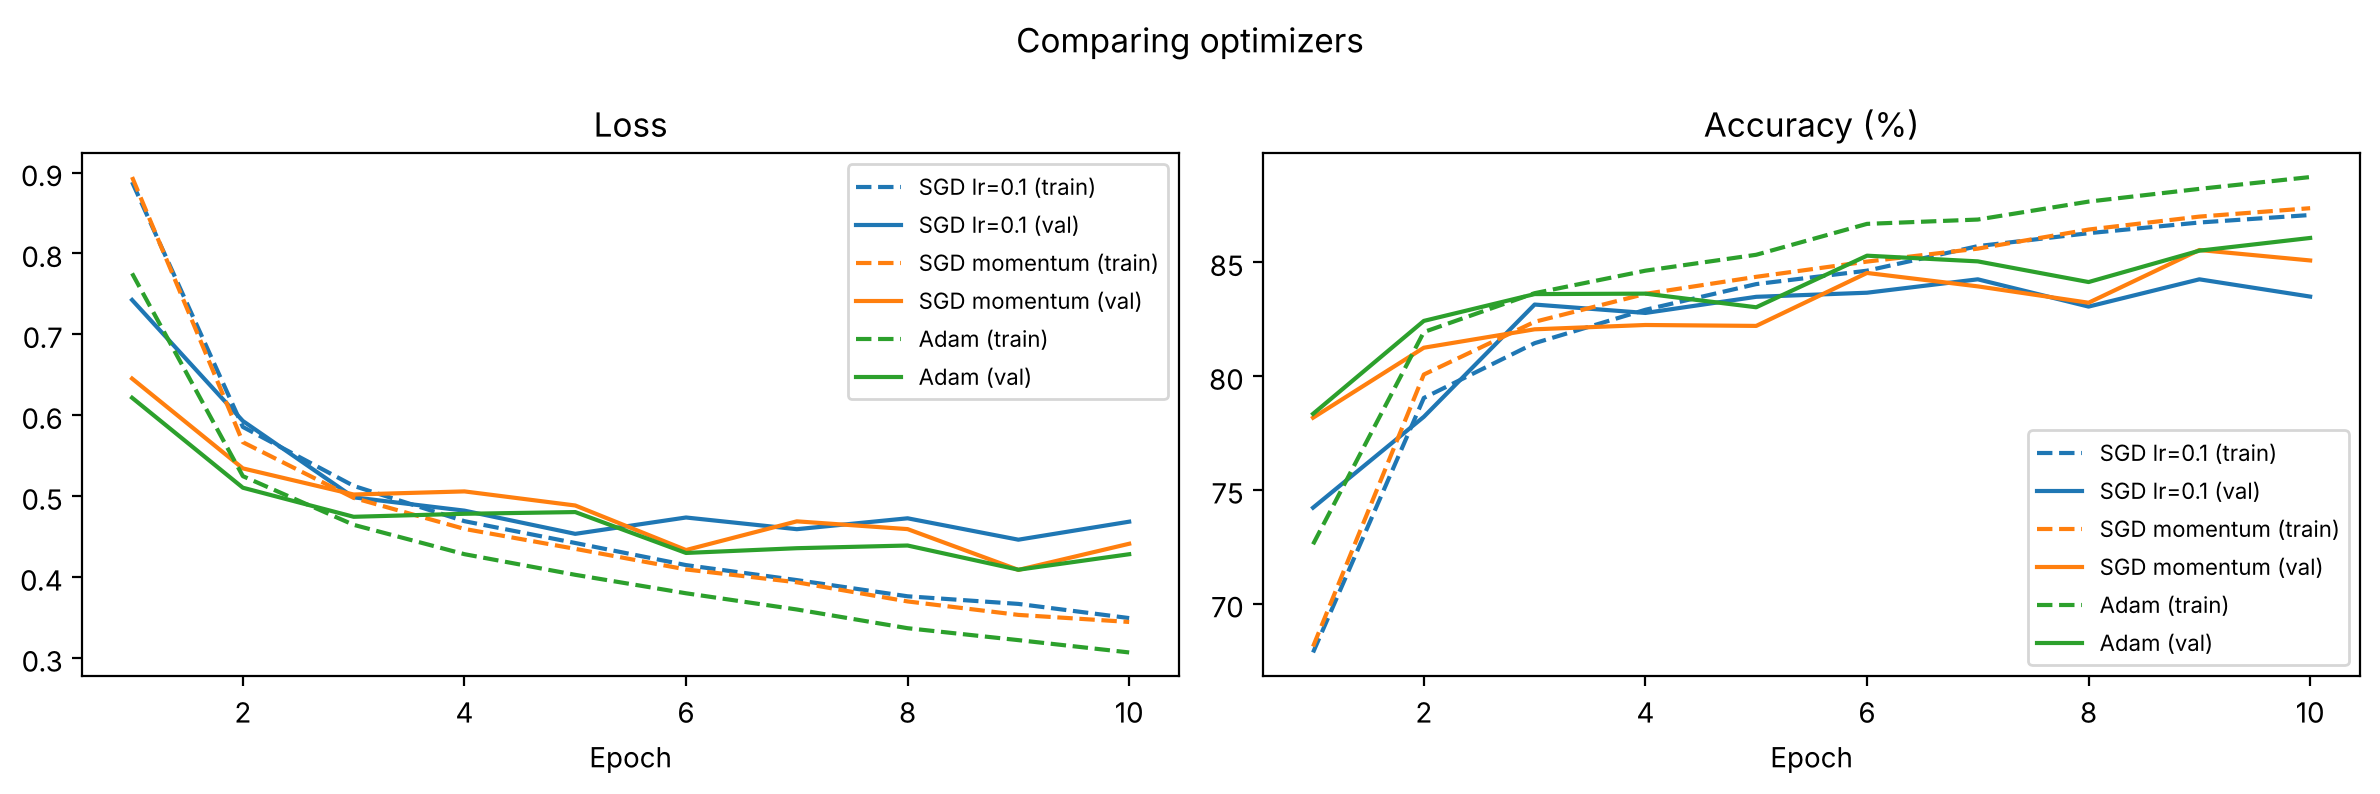

In [21]:
plot_history(opt_histories, title="Comparing optimizers")

Adam reaches a lower validation loss and higher accuracy than plain SGD at every epoch, with momentum in between, but on a small problem like this the differences are a couple of percentage points. The bigger practical difference is that Adam works well with its default learning rate, while SGD's learning rate needs tuning (we tried three values to find 0.1).

A reasonable default: **start with Adam at `lr=0.001`**. If the loss is flat, try a larger learning rate. If it jumps around or blows up, try a smaller one.

Notice also that training accuracy (dashed) is starting to pull ahead of validation accuracy (solid), and plain SGD's validation loss is already creeping back up. Even 10,000 images is a small dataset. Time to deal with that.

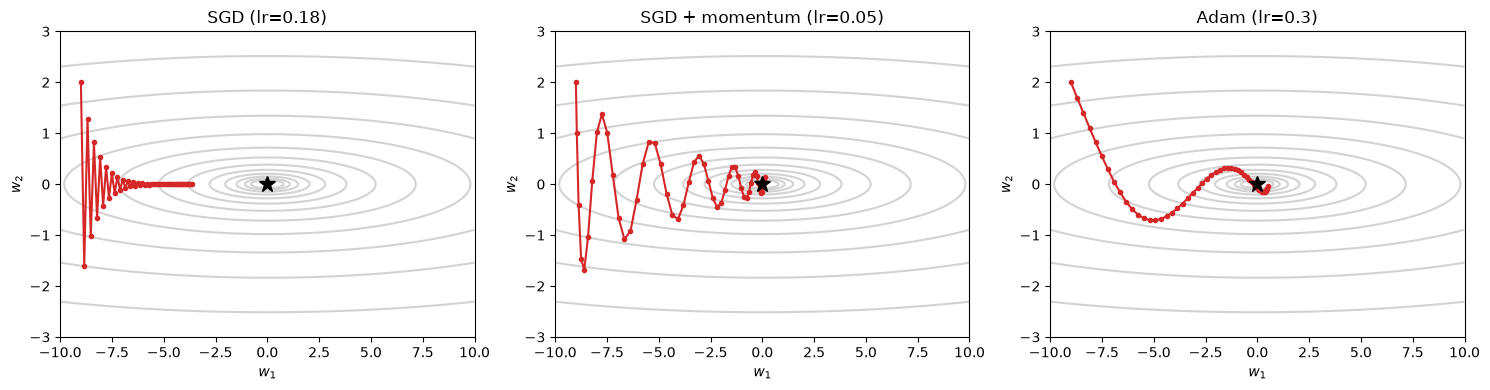

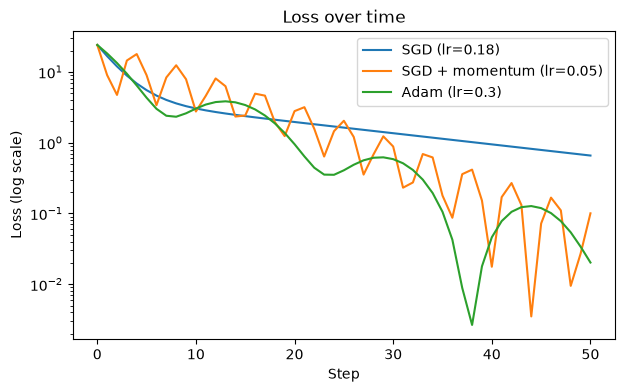

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# A long, narrow valley: steep in w2, shallow in w1. Minimum at (0, 0).
def loss(w):
    return 0.05 * w[0]**2 + 5 * w[1]**2

def grad(w):
    return np.array([0.1 * w[0], 10 * w[1]])

def sgd(w0, lr, steps):
    w = np.array(w0, dtype=float)
    path = [w.copy()]
    for _ in range(steps):
        w = w - lr * grad(w)
        path.append(w.copy())
    return np.array(path)

def momentum(w0, lr, steps, beta=0.9):
    w = np.array(w0, dtype=float)
    v = np.zeros_like(w)                 # running average of gradients ("velocity")
    path = [w.copy()]
    for _ in range(steps):
        v = beta * v + grad(w)
        w = w - lr * v
        path.append(w.copy())
    return np.array(path)

def adam(w0, lr, steps, beta1=0.9, beta2=0.999, eps=1e-8):
    w = np.array(w0, dtype=float)
    m = np.zeros_like(w)                 # running average of gradients (like momentum)
    s = np.zeros_like(w)                 # running average of squared gradients
    path = [w.copy()]
    for t in range(1, steps + 1):
        g = grad(w)
        m = beta1 * m + (1 - beta1) * g
        s = beta2 * s + (1 - beta2) * g**2
        m_hat = m / (1 - beta1**t)       # bias correction for the first few steps
        s_hat = s / (1 - beta2**t)
        w = w - lr * m_hat / (np.sqrt(s_hat) + eps)   # each parameter gets its own step size
        path.append(w.copy())
    return np.array(path)

w0, steps = (-9.0, 2.0), 50
paths = {
    "SGD (lr=0.18)":            sgd(w0, lr=0.18, steps=steps),
    "SGD + momentum (lr=0.05)": momentum(w0, lr=0.05, steps=steps),
    "Adam (lr=0.3)":            adam(w0, lr=0.3, steps=steps),
}

# Loss surface for the contour plots
w1, w2 = np.meshgrid(np.linspace(-10, 10, 300), np.linspace(-3, 3, 300))
L = loss([w1, w2])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, path) in zip(axes, paths.items()):
    ax.contour(w1, w2, L, levels=np.logspace(-1.5, 1.5, 12), colors="lightgray")
    ax.plot(path[:, 0], path[:, 1], "o-", color="C3", markersize=3)
    ax.plot(0, 0, "k*", markersize=12)
    ax.set_title(title)
    ax.set_xlabel("$w_1$")
    ax.set_ylabel("$w_2$")
    ax.set_xlim(-10, 10)
    ax.set_ylim(-3, 3)
plt.tight_layout()
plt.show()

# Loss over steps
plt.figure(figsize=(7, 4))
for title, path in paths.items():
    plt.plot([loss(w) for w in path], label=title)
plt.yscale("log")
plt.xlabel("Step")
plt.ylabel("Loss (log scale)")
plt.title("Loss over time")
plt.legend()
plt.show()

## Regularization

**Regularization** is any technique that makes it harder for a model to memorize the training data, nudging it toward patterns that generalize. We'll go back to our overfitting setup (the 512x512 model on 2,000 images) and try two of the most common techniques.

### Dropout

**Dropout** randomly sets a fraction $p$ of a layer's outputs to zero on every training step. Because any neuron might disappear at any time, the network can't rely on a few specific neurons to memorize particular examples. It has to spread what it learns across many neurons, which tends to generalize better.

Dropout is only active during training. At evaluation time every neuron is used. This is exactly why `model.train()` and `model.eval()` matter:

In [26]:
dropout = nn.Dropout(p=0.5)
x = torch.ones(10)

torch.manual_seed(0)
dropout.train()
print("Training mode:  ", dropout(x))

dropout.eval()
print("Evaluation mode:", dropout(x))

Training mode:   tensor([0., 0., 2., 0., 0., 0., 2., 2., 0., 2.])
Evaluation mode: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


In training mode, about half the values are zeroed. The survivors are scaled up by $\frac{1}{1-p} = 2$ so the expected total stays the same. In evaluation mode, dropout does nothing.

Our `make_big_model()` function already takes a `dropout` argument that inserts `nn.Dropout()` after each hidden layer.

In [27]:
torch.manual_seed(42)
dropout_model = make_big_model(dropout=0.5)
print(dropout_model)

optimizer = torch.optim.Adam(dropout_model.parameters(), lr=0.001)
dropout_history = fit(dropout_model, small_train_dataloader, val_dataloader, loss_fn, optimizer, epochs=30)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=512, out_features=512, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.5, inplace=False)
  (7): Linear(in_features=512, out_features=10, bias=True)
)
Epoch  0 | Train loss: 1.3846, acc: 47.57% | Val loss: 0.8385, acc: 66.86%
Epoch  5 | Train loss: 0.5625, acc: 79.71% | Val loss: 0.5353, acc: 81.52%
Epoch 10 | Train loss: 0.4634, acc: 82.04% | Val loss: 0.5391, acc: 81.48%
Epoch 15 | Train loss: 0.3986, acc: 84.28% | Val loss: 0.5105, acc: 82.77%
Epoch 20 | Train loss: 0.3529, acc: 87.25% | Val loss: 0.5297, acc: 82.97%
Epoch 25 | Train loss: 0.3482, acc: 87.80% | Val loss: 0.5315, acc: 83.48%
Epoch 29 | Train loss: 0.3263, acc: 87.85% | Val loss: 0.5112, acc: 83.55%


### Weight Decay

Overfit models tend to have some very large weights, which let them react strongly to tiny details of particular training examples. **Weight decay** (also called **L2 regularization**) discourages this by shrinking every weight a little toward zero on each step. You can think of it as adding a penalty to the loss for large weights:

$$L_{\text{total}} = L_{\text{data}} + \lambda \sum_i w_i^2$$

In PyTorch, weight decay is an argument to the optimizer. With Adam, use the `AdamW` variant, which applies weight decay the right way for Adam.

`AdamW` multiplies the weight decay by the learning rate, so each step shrinks the weights by `lr * weight_decay` = 0.001 x 1.0 = 0.1%. That's why the number below looks large; values from 0.01 to 1.0 are common with `AdamW`.

In [28]:
WEIGHT_DECAY = 1.0

torch.manual_seed(42)
wd_model = make_big_model()
optimizer = torch.optim.AdamW(wd_model.parameters(), lr=0.001, weight_decay=WEIGHT_DECAY)
wd_history = fit(wd_model, small_train_dataloader, val_dataloader, loss_fn, optimizer, epochs=30)

Epoch  0 | Train loss: 1.1141, acc: 59.47% | Val loss: 0.7898, acc: 72.09%
Epoch  5 | Train loss: 0.4819, acc: 82.39% | Val loss: 0.5732, acc: 80.33%
Epoch 10 | Train loss: 0.3568, acc: 86.51% | Val loss: 0.5143, acc: 82.39%
Epoch 15 | Train loss: 0.3150, acc: 88.14% | Val loss: 0.5559, acc: 79.80%
Epoch 20 | Train loss: 0.2789, acc: 89.43% | Val loss: 0.5174, acc: 82.84%
Epoch 25 | Train loss: 0.2545, acc: 90.38% | Val loss: 0.6234, acc: 82.07%
Epoch 29 | Train loss: 0.2594, acc: 90.62% | Val loss: 0.5918, acc: 79.88%


We can see the effect directly by comparing the weights of the first layer with and without weight decay:

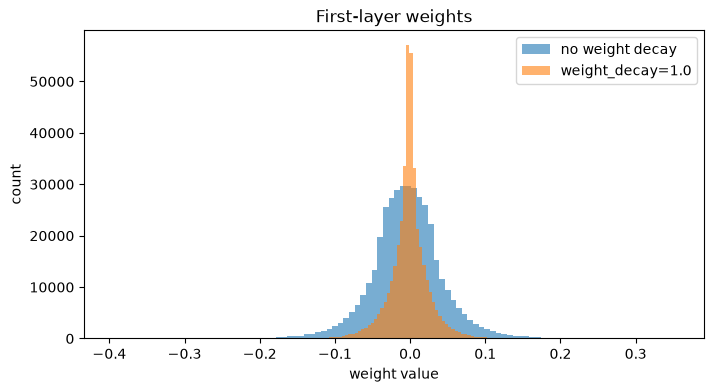

In [29]:
plt.figure(figsize=(8, 4))
plt.hist(big_model[1].weight.detach().cpu().flatten(), bins=100, alpha=0.6, label="no weight decay")
plt.hist(wd_model[1].weight.detach().cpu().flatten(), bins=100, alpha=0.6, label=f"weight_decay={WEIGHT_DECAY}")
plt.xlabel("weight value")
plt.ylabel("count")
plt.title("First-layer weights")
plt.legend()
plt.show()

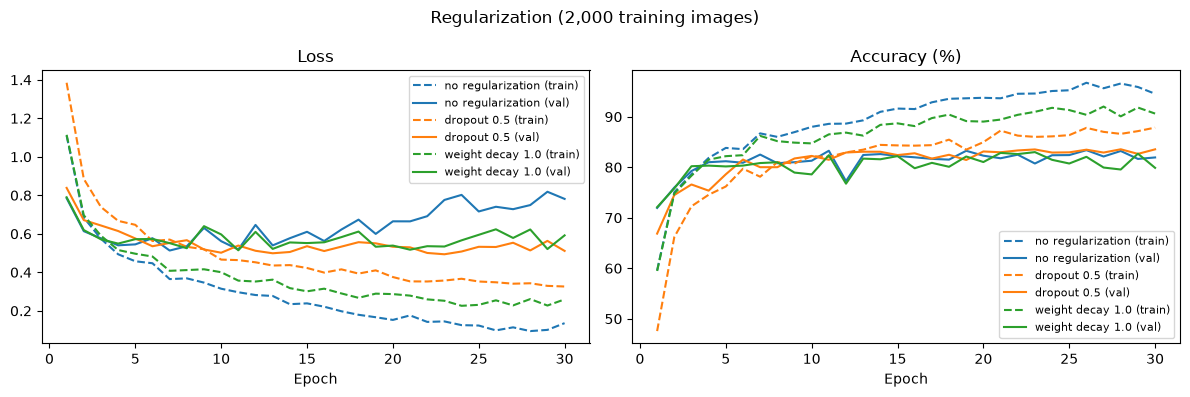

In [30]:
plot_history({"no regularization": big_history,
              "dropout 0.5": dropout_history,
              f"weight decay {WEIGHT_DECAY}": wd_history},
             title="Regularization (2,000 training images)")

In [31]:
def summarize(histories: dict):
    rows = []
    for name, h in histories.items():
        rows.append({"model": name,
                     "final train acc": h["train_acc"][-1],
                     "final val acc": h["val_acc"][-1],
                     "gap": h["train_acc"][-1] - h["val_acc"][-1],
                     "best val acc": max(h["val_acc"]),
                     "final val loss": h["val_loss"][-1]})
    return pd.DataFrame(rows).set_index("model").round(2)

summarize({"no regularization": big_history,
           "dropout 0.5": dropout_history,
           f"weight decay {WEIGHT_DECAY}": wd_history})

,final train acc,final val acc,gap,best val acc,final val loss
model,,,,,
no regularization,94.54,81.94,12.60,83.39,0.78
dropout 0.5,87.85,83.55,4.30,83.56,0.51
weight decay 1.0,90.62,79.88,10.74,83.00,0.59


Comparing the three models:

- **Dropout** made the biggest difference. The gap between training and validation accuracy shrank from about 12 points to about 4, and validation loss stayed much lower instead of climbing. Training accuracy is lower, which is expected: the model is working with half its neurons switched off on every step.
- **Weight decay** pulled the weights toward zero (see the histogram) and kept the validation loss from climbing as high, but on its own it barely closed the accuracy gap here.
- Notice that **best validation accuracy is about the same for all three** (~83-84%). With only 2,000 images, there's a ceiling on how well any model can do. Regularization doesn't add information; it stops the model from getting *worse* by memorizing, which makes the result more reliable and less dependent on exactly when you stop training.

Not every technique helps every problem. That's why we compare on a validation set rather than assuming.

## Data Augmentation

The best cure for overfitting is more data. Collecting more labeled images is expensive, but we can often create "new" training examples by transforming the ones we have in ways that don't change the label. A shirt flipped left-to-right is still a shirt; a shoe shifted a few pixels is still a shoe.

`torchvision.transforms` has many of these. We'll combine a random horizontal flip with a small random rotation and shift:

In [32]:
augment = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=5, translate=(0.05, 0.05)),  # rotate up to 5 degrees, shift up to 5%
    ToTensor()
])

# A second copy of the training data that applies the augmentation every time an image is loaded
train_data_augmented = datasets.FashionMNIST(root="data", train=True, download=True, transform=augment)

Let's see what the augmentation does to one image. Every time we load it, we get a slightly different version:

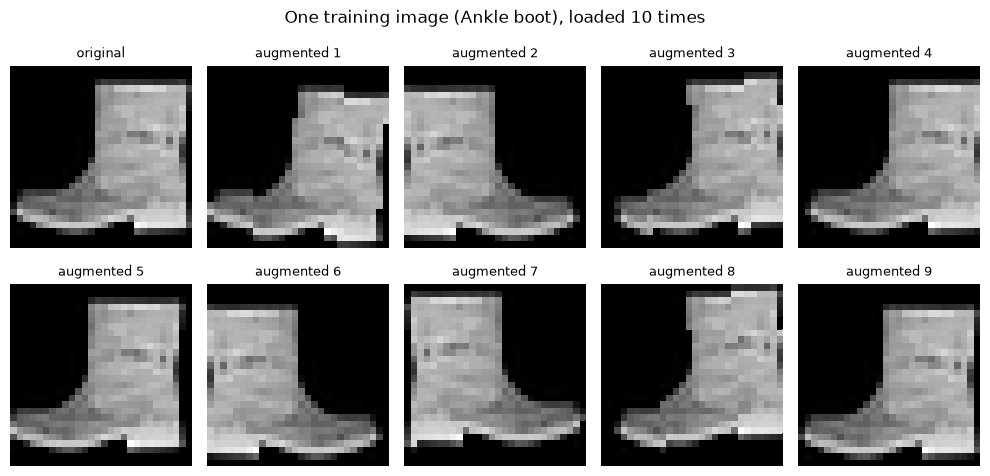

In [33]:
idx = small_indices[0]

torch.manual_seed(42)
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    img, label = train_data[idx] if i == 0 else train_data_augmented[idx]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title("original" if i == 0 else f"augmented {i}", fontsize=9)
    ax.axis(False)
fig.suptitle(f"One training image ({class_names[label]}), loaded 10 times")
plt.tight_layout(h_pad=1.5)
plt.show()

We train on the **same 2,000 images** as before, but each epoch the model sees a fresh random variation of each one, so it can't memorize exact pixels.

Note that we only augment the **training** data. The validation and test sets stay unchanged, since we want to measure performance on real, untouched images.

In [34]:
small_train_augmented = Subset(train_data_augmented, small_indices)  # same 2,000 images, augmented
small_train_augmented_dataloader = DataLoader(small_train_augmented, batch_size=BATCH_SIZE, shuffle=True)

torch.manual_seed(42)
aug_model = make_big_model()
optimizer = torch.optim.Adam(aug_model.parameters(), lr=0.001)
aug_history = fit(aug_model, small_train_augmented_dataloader, val_dataloader, loss_fn, optimizer, epochs=30)

Epoch  0 | Train loss: 1.2902, acc: 50.64% | Val loss: 0.9357, acc: 63.16%
Epoch  5 | Train loss: 0.6402, acc: 75.55% | Val loss: 0.6220, acc: 77.61%
Epoch 10 | Train loss: 0.5654, acc: 77.93% | Val loss: 0.5564, acc: 80.52%
Epoch 15 | Train loss: 0.4951, acc: 80.51% | Val loss: 0.5315, acc: 81.24%
Epoch 20 | Train loss: 0.4741, acc: 81.05% | Val loss: 0.5465, acc: 80.94%
Epoch 25 | Train loss: 0.4303, acc: 84.13% | Val loss: 0.5446, acc: 81.05%
Epoch 29 | Train loss: 0.3954, acc: 83.93% | Val loss: 0.5963, acc: 82.27%


Regularization techniques can be combined. Let's try augmentation together with dropout:

In [35]:
torch.manual_seed(42)
aug_dropout_model = make_big_model(dropout=0.5)
optimizer = torch.optim.Adam(aug_dropout_model.parameters(), lr=0.001)
aug_dropout_history = fit(aug_dropout_model, small_train_augmented_dataloader, val_dataloader,
                          loss_fn, optimizer, epochs=30)

Epoch  0 | Train loss: 1.5999, acc: 39.48% | Val loss: 1.0606, acc: 59.80%
Epoch  5 | Train loss: 0.8108, acc: 68.70% | Val loss: 0.6705, acc: 74.41%
Epoch 10 | Train loss: 0.7585, acc: 70.59% | Val loss: 0.6093, acc: 76.62%
Epoch 15 | Train loss: 0.6810, acc: 73.66% | Val loss: 0.5700, acc: 79.33%
Epoch 20 | Train loss: 0.6568, acc: 74.65% | Val loss: 0.5568, acc: 79.81%
Epoch 25 | Train loss: 0.6251, acc: 75.64% | Val loss: 0.5567, acc: 80.06%
Epoch 29 | Train loss: 0.6011, acc: 76.79% | Val loss: 0.5336, acc: 80.93%


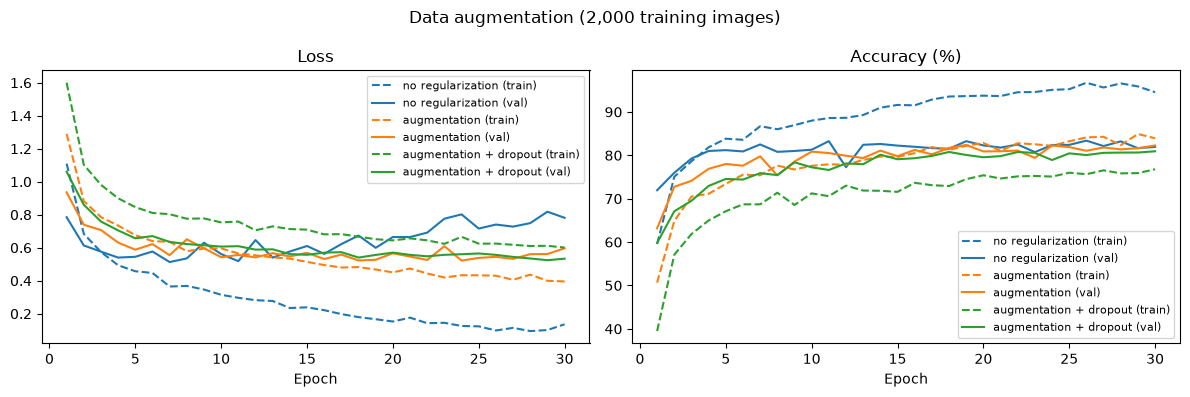

,final train acc,final val acc,gap,best val acc,final val loss
model,,,,,
no regularization,94.54,81.94,12.60,83.39,0.78
dropout 0.5,87.85,83.55,4.30,83.56,0.51
weight decay 1.0,90.62,79.88,10.74,83.00,0.59
augmentation,83.93,82.27,1.66,82.39,0.60
augmentation + dropout,76.79,80.93,-4.14,80.93,0.53


In [36]:
plot_history({"no regularization": big_history,
              "augmentation": aug_history,
              "augmentation + dropout": aug_dropout_history},
             title="Data augmentation (2,000 training images)")

summarize({"no regularization": big_history,
           "dropout 0.5": dropout_history,
           f"weight decay {WEIGHT_DECAY}": wd_history,
           "augmentation": aug_history,
           "augmentation + dropout": aug_dropout_history})

What happened:

- **Augmentation alone** shrank the train/validation gap from about 12 points to about 3. The model can no longer memorize exact pixels, so training accuracy stays much closer to validation accuracy. Validation accuracy ends up similar to the unregularized model; augmentation also slows learning, since every epoch shows the model harder examples, and it usually pays off over longer training.
- **Augmentation + dropout** goes too far: the gap is now *negative*, meaning training accuracy is below validation accuracy. That happens because training accuracy is measured on augmented images with dropout switched on, which is harder than the clean validation images with dropout off. When you see this, the model is held back by too much regularization, i.e. it's drifting into **underfitting**.

Regularization is a dial, not a switch. Too little and the model memorizes; too much and it can't learn. The validation curves tell you which way to turn it.

One more note: augmentation works especially well with CNNs, because convolutions are built to recognize the same pattern wherever it appears in the image. Our fully connected model has to learn each shifted version separately, which is part of why augmentation helped it less.

## Early Stopping

Look back at the unregularized model's validation loss: it reaches its lowest point after a few epochs, and every epoch after that makes the model *worse* on new data. So why not just stop there?

**Early stopping** does exactly that:

1. After each epoch, check the validation loss.
2. If it's the best so far, save a copy of the model's parameters.
3. If it hasn't improved for `patience` epochs in a row, stop training.
4. Restore the saved best parameters.

The parameters of a model live in its `state_dict()`. We use `copy.deepcopy()` so the saved copy doesn't keep changing as training continues.

Let's add a `patience` option to `fit()`:

In [37]:
def fit(model, train_dataloader, val_dataloader, loss_fn, optimizer,
        epochs, patience=None, print_every=5, device=device):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss, train_acc = train_step(model, train_dataloader, loss_fn, optimizer, accuracy_fn, device)
        val_loss, val_acc = test_step(model, val_dataloader, loss_fn, accuracy_fn, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if epoch % print_every == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch:2d} | Train loss: {train_loss:.4f}, acc: {train_acc:.2f}% "
                  f"| Val loss: {val_loss:.4f}, acc: {val_acc:.2f}%")

        if patience is not None:
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())  # save the best parameters
                best_epoch = epoch
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
                if epochs_without_improvement >= patience:
                    print(f"Stopping early at epoch {epoch}: no improvement for {patience} epochs.")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)  # restore the best parameters
        print(f"Restored model from epoch {best_epoch} (val loss {best_val_loss:.4f}, "
              f"val acc {history['val_acc'][best_epoch]:.2f}%)")
        history["best_epoch"] = best_epoch
    return history

In [38]:
torch.manual_seed(42)
es_model = make_big_model()
optimizer = torch.optim.Adam(es_model.parameters(), lr=0.001)

es_history = fit(es_model, small_train_dataloader, val_dataloader, loss_fn, optimizer,
                 epochs=30, patience=5, print_every=1)

Epoch  0 | Train loss: 1.1097, acc: 59.57% | Val loss: 0.7850, acc: 71.94%
Epoch  1 | Train loss: 0.6843, acc: 75.05% | Val loss: 0.6137, acc: 75.98%
Epoch  2 | Train loss: 0.5741, acc: 78.62% | Val loss: 0.5764, acc: 79.25%
Epoch  3 | Train loss: 0.4937, acc: 81.85% | Val loss: 0.5402, acc: 81.00%
Epoch  4 | Train loss: 0.4573, acc: 83.83% | Val loss: 0.5451, acc: 81.19%
Epoch  5 | Train loss: 0.4470, acc: 83.58% | Val loss: 0.5771, acc: 80.89%
Epoch  6 | Train loss: 0.3648, acc: 86.71% | Val loss: 0.5131, acc: 82.51%
Epoch  7 | Train loss: 0.3685, acc: 86.01% | Val loss: 0.5354, acc: 80.80%
Epoch  8 | Train loss: 0.3465, acc: 86.95% | Val loss: 0.6305, acc: 81.00%
Epoch  9 | Train loss: 0.3148, acc: 88.00% | Val loss: 0.5617, acc: 81.29%
Epoch 10 | Train loss: 0.2964, acc: 88.59% | Val loss: 0.5185, acc: 83.27%
Epoch 11 | Train loss: 0.2820, acc: 88.64% | Val loss: 0.6463, acc: 77.26%
Stopping early at epoch 11: no improvement for 5 epochs.
Restored model from epoch 6 (val loss 0.513

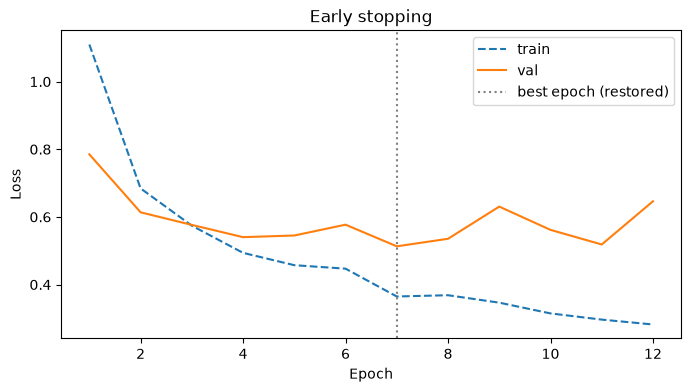

In [39]:
fig, ax = plt.subplots(figsize=(8, 4))
epochs_range = range(1, len(es_history["val_loss"]) + 1)
ax.plot(epochs_range, es_history["train_loss"], "--", label="train")
ax.plot(epochs_range, es_history["val_loss"], "-", label="val")
ax.axvline(es_history["best_epoch"] + 1, color="gray", linestyle=":", label="best epoch (restored)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Early stopping")
ax.legend()
plt.show()

Training stopped a few epochs after the validation loss bottomed out, and the model we kept is the one from the best epoch, not the last one. Early stopping also saves time: we didn't spend epochs making the model worse.

### Saving and loading a model

The same `state_dict()` is how you save a trained model to disk and load it later:

In [40]:
from pathlib import Path

model_path = Path("models")
model_path.mkdir(exist_ok=True)

# Save only the parameters (the recommended way)
torch.save(es_model.state_dict(), model_path / "lecture16_early_stopping.pth")

# To load: create a model with the same architecture, then load the parameters into it
loaded_model = make_big_model()
loaded_model.load_state_dict(torch.load(model_path / "lecture16_early_stopping.pth"))

test_step(loaded_model, val_dataloader, loss_fn, accuracy_fn)

(0.5131124949778992, 82.50798722044729)

## Putting It Together

Let's go back to the full dataset and the CNN from last lecture (TinyVGG) and train it with what we've learned:

- A **validation set** to make decisions, and the **test set** only once at the end
- **Adam** instead of SGD
- **Early stopping**, so we can set a generous epoch limit without worrying about overfitting

Last lecture, this CNN reached about **88%** test accuracy after 3 epochs of SGD.

In [41]:
class FashionMNISTModelV2(nn.Module):
    # TinyVGG from https://poloclub.github.io/cnn-explainer/ (same as Lecture 14)
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.block_1 = nn.Sequential(
            nn.Conv2d(input_shape, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*7*7, out_features=output_shape)
        )

    def forward(self, x: torch.Tensor):
        return self.classifier(self.block_2(self.block_1(x)))

In [42]:
full_train_dataloader = DataLoader(train_split, batch_size=BATCH_SIZE, shuffle=True)  # 50,000 images

torch.manual_seed(42)
cnn = FashionMNISTModelV2(input_shape=1, hidden_units=10, output_shape=len(class_names)).to(device)
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)

cnn_history = fit(cnn, full_train_dataloader, val_dataloader, loss_fn, optimizer,
                  epochs=15, patience=2, print_every=1)

Epoch  0 | Train loss: 0.5702, acc: 79.44% | Val loss: 0.4191, acc: 84.55%
Epoch  1 | Train loss: 0.3702, acc: 86.79% | Val loss: 0.3569, acc: 87.07%
Epoch  2 | Train loss: 0.3310, acc: 88.09% | Val loss: 0.3515, acc: 87.09%
Epoch  3 | Train loss: 0.3108, acc: 88.86% | Val loss: 0.3408, acc: 88.00%
Epoch  4 | Train loss: 0.2914, acc: 89.60% | Val loss: 0.3077, acc: 89.24%
Epoch  5 | Train loss: 0.2790, acc: 89.93% | Val loss: 0.2998, acc: 89.45%
Epoch  6 | Train loss: 0.2676, acc: 90.31% | Val loss: 0.2809, acc: 90.11%
Epoch  7 | Train loss: 0.2582, acc: 90.64% | Val loss: 0.2914, acc: 89.89%
Epoch  8 | Train loss: 0.2495, acc: 90.89% | Val loss: 0.2951, acc: 89.59%
Stopping early at epoch 8: no improvement for 2 epochs.
Restored model from epoch 6 (val loss 0.2809, val acc 90.11%)


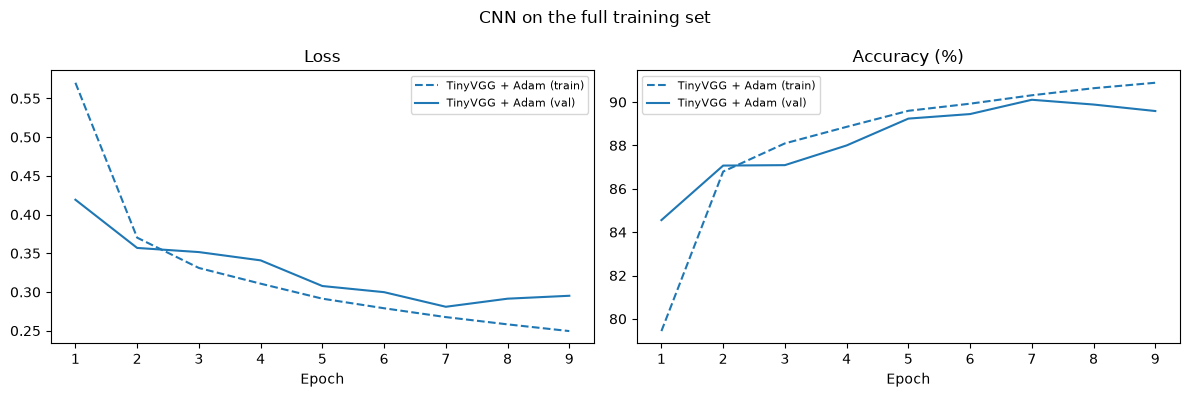

In [43]:
plot_history({"TinyVGG + Adam": cnn_history}, title="CNN on the full training set")

Now, and only now, we evaluate on the test set:

In [44]:
test_loss, test_acc = test_step(cnn, test_dataloader, loss_fn, accuracy_fn)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.2f}%")

Test loss: 0.2975 | Test accuracy: 89.35%


The CNN reached about **89%** test accuracy, up from 88% last lecture. That's a modest gain, and an honest one: last time we picked the CNN by looking at the test set, while this time the test set played no part in any decision, so 89% is a good estimate of how the model will do on new images.

Looking at the curves, train and validation loss track each other closely with no real gap. With only about 10,000 parameters and 50,000 training images, this CNN isn't overfitting; if anything it's on the **underfitting** side. That points toward a bigger model (more `hidden_units`, more layers) as the next thing to try, not more regularization. Reading the curves tells you which direction to go.

## Summary: A Training Checklist

1. **Split your data** into train / validation / test. Make decisions with the validation set; touch the test set once.
2. **Sanity check the model**: no activation after the output layer, logits look reasonable, and it can overfit a single batch.
3. **Start with Adam at `lr=0.001`.** If the loss is flat, raise the learning rate; if it's jumpy or blows up, lower it.
4. **Plot train vs. validation loss** and diagnose:
    - Both high and close together → **underfitting**: bigger model, train longer, check for bugs.
    - Train low, validation rising → **overfitting**: augmentation, dropout, weight decay, more data.
5. **Use early stopping** and keep the best model, not the last one.
6. **Call `model.train()` before training and `model.eval()` before evaluating**, since layers like dropout behave differently in each mode.
